# Experimento 04: qual é o melhor Stacking 7 *para esta caixa*?

**Pergunta.** Medindo só nesta caixa de e-mail (Enron1) e com várias sementes aleatórias, qual configuração do Stacking 7 é a melhor?

**Termos.** *E-mail real* = e-mail legítimo. `real_lixeira` = % de e-mails reais marcados como spam. `spam_passou` = % de spam que chegou à caixa de entrada. *Custo por mil* = 9 × e-mails reais na lixeira + 1 × spams que passaram, a cada 1000 e-mails.

**Como evitar o viés de seleção.** Cada etapa que escolhe algo usa divisões que a etapa seguinte não reaproveita:

| Etapa | Divisões | Papel |
|---|---|---|
| Busca (exp. 03) | sementes 11 e 12 (10 folds) | o algoritmo genético gera os candidatos |
| **Corrida** | sementes 201 e 202 (10 folds) | ordena os 10 melhores candidatos + o padrão |
| **Verificação** | sementes 203 e 204 (10 folds) | mede o vencedor da corrida contra o padrão, sem otimismo |

As seções 1 a 6 repetem o experimento 03 a partir do cache dele, sem retreinar nada. A base de teste trancada e a base externa **não** são usadas aqui.

In [1]:
import os, gc, time, hashlib, platform, numpy as np, pandas as pd, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
from scipy import sparse, stats
from joblib import Parallel, delayed, parallel_config
import psutil, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer, StandardScaler
from sklearn.naive_bayes import ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import matthews_corrcoef, average_precision_score
from lightgbm import LGBMClassifier
import baycomp, sklearn

SMOKE = bool(os.environ.get("GA_SMOKE"))          # execucao reduzida so para testar o codigo
SEED, N_THREADS = 42, 4
CUSTO_FP, CUSTO_FN = 9, 1                          # 1 e-mail real perdido = 9 spams recebidos
CACHE = Path("cache_ga_smoke" if SMOKE else "../03_ga/cache_ga").resolve(); CACHE.mkdir(exist_ok=True)
LOG = Path("progresso_ga_smoke.log" if SMOKE else "progresso_corrida.log")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

def log(msg):
    print(msg, flush=True)
    with LOG.open("a", encoding="utf-8") as fh: fh.write(time.strftime("%H:%M:%S ") + msg + "\n")
log(f"inicio | python {platform.python_version()} | sklearn {sklearn.__version__} | SMOKE={SMOKE}")

inicio | python 3.11.9 | sklearn 1.9.1 | SMOKE=False


## 1. Dados e a mesma base de teste trancada do experimento 02

In [2]:
RAIZ = next(p for p in [Path("../.."), Path(".."), Path(".")] if (p / "emails (1).csv").exists() or (p / "emails.csv").exists())
CSV = next(p for p in [RAIZ / "emails.csv", RAIZ / "emails (1).csv"] if p.exists())
df = pd.read_csv(CSV); y_all = df.pop("Prediction").values; df.pop("Email No.")
g_all = pd.util.hash_pandas_object(df, index=False).values
A = np.ascontiguousarray(df.values, dtype=np.int64)
hash_csv = {hashlib.md5(r.tobytes()).digest() for r in A}
X_all = sparse.csr_matrix(A.astype(np.float32)); del df, A; gc.collect()

ix = np.load(next(p for p in [Path("../indices_teste.npz"), Path("indices_teste.npz")] if p.exists()))
dev, teste = ix["dev"], ix["teste"]
assert len(dev) + len(teste) == len(y_all) and not set(g_all[dev]) & set(g_all[teste])
X, y, g = X_all[dev], y_all[dev], g_all[dev]
BASES = {"dev": (X, y, g), "all": (X_all, y_all, g_all)}
log(f"desenvolvimento {len(dev)} | teste trancado {len(teste)} ({(y_all[teste] == 0).sum()} reais, {(y_all[teste] == 1).sum()} spam)")

desenvolvimento 4137 | teste trancado 1035 (735 reais, 300 spam)


## 2. Espaço de busca: a árvore de parâmetros prováveis

In [3]:
tf = lambda: TfidfTransformer(sublinear_tf=True)
def lr(C, cw):          return make_pipeline(tf(), LogisticRegression(C=C, class_weight=cw, max_iter=5000))
def svm(k, C):          return make_pipeline(tf(), TruncatedSVD(k, random_state=SEED), Normalizer(), SVC(C=C, class_weight="balanced"))
def knn(k, w):          return make_pipeline(tf(), KNeighborsClassifier(k, weights=w, metric="cosine"))
def mlp(h, a):          return make_pipeline(tf(), MLPClassifier(h, alpha=a, early_stopping=True, max_iter=200, random_state=SEED))
def cnb(a, norm, usa_tf):
    return make_pipeline(tf(), ComplementNB(alpha=a, norm=norm)) if usa_tf else ComplementNB(alpha=a, norm=norm)
def et(n, mf, msl, cw): return ExtraTreesClassifier(n, max_features=mf, min_samples_leaf=msl, class_weight=cw, n_jobs=N_THREADS, random_state=SEED)
def lgbm(n, eta, folhas, col=1.0, sub=1.0, mcs=20):
    return LGBMClassifier(n_estimators=n, learning_rate=eta, num_leaves=folhas, colsample_bytree=col, subsample=sub,
                          subsample_freq=1 if sub < 1 else 0, min_child_samples=mcs, n_jobs=N_THREADS, verbose=-1, random_state=SEED)
def lsvc(C, cw):        return make_pipeline(tf(), LinearSVC(C=C, class_weight=cw))

ESPACO = {   # posicao 0 = configuracao do experimento 02
  "Reg. Logística": [(lr, dict(C=C, cw=cw)) for C, cw in
                     [(10, "balanced"), (1, "balanced"), (3, "balanced"), (30, "balanced"), (100, "balanced"), (10, None), (1, None), (100, None)]],
  "SVM RBF":        [(svm, dict(k=k, C=C)) for k, C in [(300, 10), (300, 3), (300, 30), (150, 10), (150, 30), (500, 10), (300, 1), (500, 30)]],
  "kNN cosseno":    [(knn, dict(k=k, w=w)) for k, w in
                     [(5, "uniform"), (3, "uniform"), (7, "uniform"), (11, "uniform"), (15, "uniform"), (5, "distance"), (11, "distance"), (21, "distance")]],
  "MLP":            [(mlp, dict(h=h, a=a)) for h, a in [((128,), 1e-4), ((64,), 1e-4), ((256,), 1e-4), ((128,), 1e-3), ((128,), 1e-2), ((256, 128), 1e-4)]],
  "Naive Bayes":    [(cnb, dict(a=a, norm=n, usa_tf=t)) for a, n, t in
                     [(1, False, False), (0.1, False, False), (0.3, False, False), (3, False, False), (1, True, False), (0.1, True, False), (0.1, False, True), (1, False, True)]],
  "Extra Trees":    [(et, dict(n=n, mf=mf, msl=msl, cw=cw)) for n, mf, msl, cw in
                     [(400, "sqrt", 1, "balanced"), (400, "sqrt", 1, None), (400, "log2", 1, "balanced"), (400, 0.05, 1, "balanced"), (400, "sqrt", 2, "balanced"), (800, "sqrt", 1, "balanced")]],
  "LightGBM":       [(lgbm, kw) for kw in
                     [dict(n=400, eta=0.05, folhas=31), dict(n=200, eta=0.1, folhas=31), dict(n=800, eta=0.03, folhas=31), dict(n=400, eta=0.05, folhas=15),
                      dict(n=400, eta=0.05, folhas=63), dict(n=400, eta=0.05, folhas=31, col=0.3), dict(n=800, eta=0.05, folhas=15, col=0.3, sub=0.8),
                      dict(n=400, eta=0.05, folhas=31, mcs=5)]],
}
LINEARSVC = [(lsvc, dict(C=C, cw=cw)) for C, cw in [(1, "balanced"), (0.1, "balanced"), (0.3, "balanced"), (3, "balanced"), (10, "balanced"), (1, None), (0.3, None), (3, None)]]
META_C = [1.0, 0.03, 0.1, 0.3, 3.0, 10.0]
if SMOKE:
    ESPACO = {f: v[:2] for f, v in ESPACO.items()}; LINEARSVC = LINEARSVC[:2]; META_C = META_C[:2]
FAMILIAS = list(ESPACO)
TODOS = {**ESPACO, "LinearSVC": LINEARSVC}
FID = {f: i for i, f in enumerate(TODOS)}
CARD = [len(ESPACO[f]) for f in FAMILIAS] + [len(META_C)]
desc = lambda fam, k: ", ".join(f"{a}={b}" for a, b in TODOS[fam][k][1].items())

print(pd.DataFrame([dict(familia=f, opcoes=len(v), padrao=desc(f, 0)) for f, v in TODOS.items()]
                   + [dict(familia="meta-modelo (C)", opcoes=len(META_C), padrao=f"C={META_C[0]}")]).to_string(index=False))
print(f"\ncombinações possíveis do Stacking 7: {int(np.prod(CARD)):,}".replace(",", "."))

        familia  opcoes                             padrao
 Reg. Logística       8                  C=10, cw=balanced
        SVM RBF       8                        k=300, C=10
    kNN cosseno       8                     k=5, w=uniform
            MLP       6                 h=(128,), a=0.0001
    Naive Bayes       8      a=1, norm=False, usa_tf=False
    Extra Trees       6 n=400, mf=sqrt, msl=1, cw=balanced
       LightGBM       8         n=400, eta=0.05, folhas=31
      LinearSVC       8                   C=1, cw=balanced
meta-modelo (C)       6                              C=1.0

combinações possíveis do Stacking 7: 7.077.888


## 3. Motor: treina cada configuração uma vez por divisão e guarda as notas em cache

In [4]:
def nota(m, A):
    return m.predict_proba(A)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(A)

def arq(chave, fam, k):
    return CACHE / f"{chave}__f{FID[fam]}__k{k}.npz"

def tarefa(chave, Xtr, ytr, gtr, tes, si, fam, k):
    """Nota out-of-fold no treino (CV interna por grupo, igual para todas as configuracoes) + nota em cada teste."""
    destino = arq(chave, fam, k)
    if destino.exists(): return
    f, kw = TODOS[fam][k]; t0 = time.time(); ztr = np.zeros(Xtr.shape[0])
    for itr, ite in StratifiedGroupKFold(5, shuffle=True, random_state=si).split(Xtr, ytr, gtr):
        m = f(**kw).fit(Xtr[itr], ytr[itr]); ztr[ite] = nota(m, Xtr[ite])
    m = f(**kw).fit(Xtr, ytr)
    tmp = destino.with_name(destino.stem + "_tmp.npz")
    np.savez(tmp, ztr=ztr, t=time.time() - t0, **{f"zte_{n}": nota(m, A) for n, A in tes.items()})
    os.replace(tmp, destino)

SPLITS = {}   # chave -> dict(base, tr, tes, si)
def args(chave, fam, k):
    sp = SPLITS[chave]; Xb, yb, gb = BASES[sp["base"]]; tr = sp["tr"]
    tes = {n: (Xb[v] if isinstance(v, np.ndarray) and v.ndim == 1 else v) for n, v in sp["tes"].items()}
    return chave, Xb[tr], yb[tr], gb[tr], tes, sp["si"], fam, k

LENTO = {"Extra Trees": 0, "LightGBM": 1, "MLP": 2, "SVM RBF": 3}
def rodar(tarefas, rotulo, blocos=8):
    """Executa em blocos; a cada bloco escolhe quantos processos usar pela RAM livre."""
    global N_THREADS
    pend = sorted([t for t in tarefas if not arq(*t).exists()], key=lambda t: LENTO.get(t[1], 9))
    log(f"{rotulo}: {len(tarefas)} tarefas, {len(pend)} pendentes")
    t_ini = time.time()
    for q in range(blocos):
        bloco = pend[q::blocos]
        if not bloco: continue
        livre = psutil.virtual_memory().available / 2**30
        nw = 4 if livre > 5 else 3 if livre > 3.5 else 2 if livre > 2.5 else 1
        N_THREADS = 4 if nw == 1 else 2; t0 = time.time()
        if nw == 1:
            for t in bloco: tarefa(*args(*t))
        else:
            with parallel_config(backend="loky", inner_max_num_threads=N_THREADS):
                Parallel(n_jobs=nw)(delayed(tarefa)(*args(*t)) for t in bloco)
        gc.collect()
        log(f"{rotulo}: bloco {q + 1}/{blocos} ok | {len(bloco)} tarefas | {nw} em paralelo | RAM livre {livre:.1f} GB | "
            f"{time.time() - t0:.0f}s (total {time.time() - t_ini:.0f}s)")

def carregar(chave, fam, k, te):
    z = np.load(arq(chave, fam, k)); return z["ztr"], z[f"zte_{te}"]

def mcc_np(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    tp = np.sum(a & b); tn = np.sum(~a & ~b); fp = np.sum(~a & b); fn = np.sum(a & ~b)
    den = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return (tp * tn - fp * fn) / den if den else 0.0

## 4. Busca: 10 divisões (2 sementes × 5 folds) com todas as configurações

In [5]:
BUSCA_SEEDS = [11] if SMOKE else [11, 12]
for s in BUSCA_SEEDS:
    for f, (tr, te) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=s).split(X, y, g)):
        if SMOKE and f >= 2: break
        SPLITS[f"b{s}_{f}"] = dict(base="dev", tr=tr, tes={"te": te}, si=s * 100 + f)
BUSCA = [c for c in SPLITS if c.startswith("b")]
rodar([(c, fam, k) for c in BUSCA for fam in TODOS for k in range(len(TODOS[fam]))], "busca")

ZB = {c: {fam: [carregar(c, fam, k, "te") for k in range(len(TODOS[fam]))] for fam in TODOS} for c in BUSCA}
YB = {c: (y[SPLITS[c]["tr"]], y[SPLITS[c]["tes"]["te"]]) for c in BUSCA}
tempo = pd.Series({f"{fam} | {desc(fam, k)}": np.mean([float(np.load(arq(c, fam, k))["t"]) for c in BUSCA])
                   for fam in TODOS for k in range(len(TODOS[fam]))})
print("tempo médio por configuração e divisão (6 treinos), as 8 mais lentas:")
print(tempo.sort_values(ascending=False).head(8).round(1).to_string())

busca: 600 tarefas, 0 pendentes


tempo médio por configuração e divisão (6 treinos), as 8 mais lentas:
Extra Trees | n=800, mf=sqrt, msl=1, cw=balanced    62.3
Extra Trees | n=400, mf=0.05, msl=1, cw=balanced    51.1
Extra Trees | n=400, mf=sqrt, msl=1, cw=balanced    33.1
LightGBM | n=800, eta=0.03, folhas=31               30.6
MLP | h=(256,), a=0.0001                            26.4
Extra Trees | n=400, mf=sqrt, msl=2, cw=balanced    26.0
Extra Trees | n=400, mf=log2, msl=1, cw=balanced    25.2
Extra Trees | n=400, mf=sqrt, msl=1, cw=None        24.8


## 5. Algoritmo genético × busca aleatória (mesmo orçamento)

GA: 857 avaliações únicas em 95s


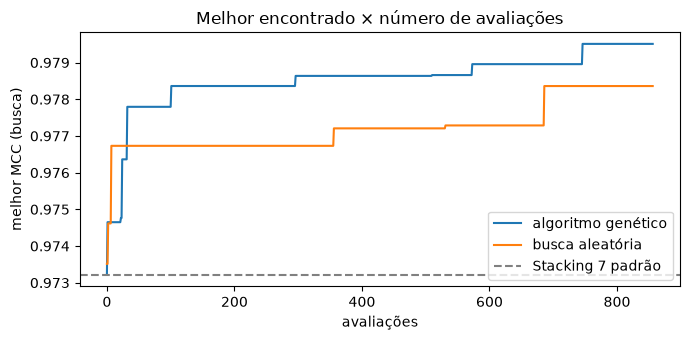

MCC na busca | padrão 0.9732 | melhor do GA 0.9795 | melhor da busca aleatória 0.9784

configuração escolhida pelo GA:
  Reg. Logística  C=1, cw=balanced
  SVM RBF         k=500, C=30
  kNN cosseno     k=3, w=uniform
  MLP             h=(64,), a=0.0001
  Naive Bayes     a=0.1, norm=True, usa_tf=False
  Extra Trees     n=800, mf=sqrt, msl=1, cw=balanced
  LightGBM        n=400, eta=0.05, folhas=63
  meta-modelo     C=10.0


In [6]:
AVAL = {}   # memoria: cromossomo -> MCC medio nas 10 divisoes de busca
def meta(C): return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
def aptidao(gen):
    gen = tuple(int(v) for v in gen)
    if gen not in AVAL:
        v = []
        for c in BUSCA:
            Ztr = np.column_stack([ZB[c][fam][gen[i]][0] for i, fam in enumerate(FAMILIAS)])
            Zte = np.column_stack([ZB[c][fam][gen[i]][1] for i, fam in enumerate(FAMILIAS)])
            p = meta(META_C[gen[-1]]).fit(Ztr, YB[c][0]).predict_proba(Zte)[:, 1]
            v.append(mcc_np(YB[c][1], p > 0.5))
        AVAL[gen] = float(np.mean(v))
    return AVAL[gen]

PADRAO = tuple([0] * len(CARD))
def algoritmo_genetico(n_pop, n_ger, p_cruz=0.9, p_mut=0.15, elite=2, seed=SEED):
    rng = np.random.default_rng(seed)
    pop = [PADRAO] + [tuple(int(rng.integers(c)) for c in CARD) for _ in range(n_pop - 1)]
    hist = []
    for ger in range(n_ger):
        apt = np.array([aptidao(i) for i in pop]); ordem = np.argsort(-apt)
        hist.append(dict(geracao=ger, melhor=apt[ordem[0]], media=apt.mean(), avaliacoes=len(AVAL)))
        def torneio():
            c = rng.choice(len(pop), 3, replace=False); return pop[c[np.argmax(apt[c])]]
        nova = [pop[i] for i in ordem[:elite]]
        while len(nova) < n_pop:
            a, b = torneio(), torneio()
            filho = tuple(x if m else z for x, z, m in zip(a, b, rng.random(len(CARD)) < 0.5)) if rng.random() < p_cruz else a
            nova.append(tuple(int(rng.integers(c)) if rng.random() < p_mut else x for x, c in zip(filho, CARD)))
        pop = nova
    apt = np.array([aptidao(i) for i in pop])
    return pop[int(np.argmax(apt))], pd.DataFrame(hist)

t0 = time.time()
melhor_ga, hist_ga = algoritmo_genetico(*((6, 3) if SMOKE else (40, 30)))
seq_ga = list(AVAL.values()); n_orc = len(seq_ga)
rng = np.random.default_rng(SEED + 1)
seq_al = [aptidao(tuple(int(rng.integers(c)) for c in CARD)) for _ in range(n_orc)]
log(f"GA: {n_orc} avaliações únicas em {time.time() - t0:.0f}s")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.maximum.accumulate(seq_ga), label="algoritmo genético")
ax.plot(np.maximum.accumulate(seq_al), label="busca aleatória")
ax.axhline(aptidao(PADRAO), color="gray", ls="--", label="Stacking 7 padrão")
ax.set_xlabel("avaliações"); ax.set_ylabel("melhor MCC (busca)"); ax.legend(); ax.set_title("Melhor encontrado × número de avaliações")
plt.tight_layout(); plt.show()

print(f"MCC na busca | padrão {aptidao(PADRAO):.4f} | melhor do GA {aptidao(melhor_ga):.4f} | melhor da busca aleatória {max(seq_al):.4f}")
print("\nconfiguração escolhida pelo GA:")
for i, fam in enumerate(FAMILIAS):
    print(f"  {fam:15s} {desc(fam, melhor_ga[i])}" + ("   (= padrão)" if melhor_ga[i] == 0 else ""))
print(f"  {'meta-modelo':15s} C={META_C[melhor_ga[-1]]}" + ("   (= padrão)" if melhor_ga[-1] == 0 else ""))

In [7]:
# Sensibilidade: partindo do melhor do GA, troca um gene por vez. Mostra quais familias importam.
sens = []
for i, nome in enumerate(FAMILIAS + ["meta-modelo (C)"]):
    v = [aptidao(melhor_ga[:i] + (k,) + melhor_ga[i + 1:]) for k in range(CARD[i])]
    sens.append(dict(gene=nome, pior=min(v), melhor=max(v), amplitude=max(v) - min(v)))
print("quanto o MCC da busca varia trocando só a configuração de uma família:")
print(pd.DataFrame(sens).sort_values("amplitude", ascending=False).round(4).to_string(index=False))

# LinearSVC tambem e afinado (comparacao justa): melhor C nas mesmas 10 divisoes
mcc_lsvc = [np.mean([mcc_np(YB[c][1], ZB[c]["LinearSVC"][k][1] > 0) for c in BUSCA]) for k in range(len(LINEARSVC))]
lsvc_best = int(np.argmax(mcc_lsvc))
print(f"\nLinearSVC na busca | padrão ({desc('LinearSVC', 0)}) {mcc_lsvc[0]:.4f} | melhor ({desc('LinearSVC', lsvc_best)}) {mcc_lsvc[lsvc_best]:.4f}")

quanto o MCC da busca varia trocando só a configuração de uma família:
           gene   pior  melhor  amplitude
    kNN cosseno 0.9740  0.9795     0.0055
        SVM RBF 0.9749  0.9795     0.0046
meta-modelo (C) 0.9755  0.9795     0.0040
       LightGBM 0.9763  0.9801     0.0038
            MLP 0.9760  0.9795     0.0035
 Reg. Logística 0.9772  0.9795     0.0023
    Naive Bayes 0.9778  0.9795     0.0018
    Extra Trees 0.9780  0.9795     0.0015

LinearSVC na busca | padrão (C=1, cw=balanced) 0.9619 | melhor (C=1, cw=None) 0.9638


## 6. Confirmação com sementes novas (20 folds que a busca não viu)
O ganho medido na própria busca é otimista: o GA escolheu o melhor de mais de mil candidatos nas mesmas 10 divisões. A medida honesta vem de divisões novas.

In [8]:
METODOS = {"Stacking 7 padrão": ("stack", PADRAO), "Stacking 7 otimizado (GA)": ("stack", melhor_ga),
           "LinearSVC padrão": ("lsvc", 0), "LinearSVC otimizado": ("lsvc", lsvc_best)}
PRECISA = sorted({(fam, 0) for fam in FAMILIAS} | {(fam, melhor_ga[i]) for i, fam in enumerate(FAMILIAS)}
                 | {("LinearSVC", 0), ("LinearSVC", lsvc_best)}, key=str)

def limiar_custo(s, yv):
    """Limiar que minimiza 9 x (reais na lixeira) + 1 x (spams que passaram), escolhido so com o treino."""
    o = np.argsort(-s); ss, yy = s[o], yv[o]
    custo = CUSTO_FP * np.cumsum(yy == 0) + CUSTO_FN * ((yy == 1).sum() - np.cumsum(yy == 1))
    i = int(np.argmin(custo))
    if CUSTO_FN * (yy == 1).sum() <= custo[i]: return np.inf
    return (ss[i] + ss[i + 1]) / 2 if i + 1 < len(ss) else ss[i] - 1e-9

def prever(metodo, chave, te):
    """(nota, decisao no limiar padrao, decisao no limiar de custo)."""
    tipo, cfg = METODOS[metodo]; sp = SPLITS[chave]; ytr = BASES[sp["base"]][1][sp["tr"]]
    if tipo == "lsvc":
        ztr, zte = carregar(chave, "LinearSVC", cfg, te)
        return zte, (zte > 0).astype(int), (zte > limiar_custo(ztr, ytr)).astype(int)
    par = [carregar(chave, fam, cfg[i], te) for i, fam in enumerate(FAMILIAS)]
    Ztr, Zte = np.column_stack([a for a, _ in par]), np.column_stack([b for _, b in par])
    m = meta(META_C[cfg[-1]])
    oof = cross_val_predict(m, Ztr, ytr, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    p = m.fit(Ztr, ytr).predict_proba(Zte)[:, 1]
    return p, (p > 0.5).astype(int), (p > limiar_custo(oof, ytr)).astype(int)

def metricas(yv, s, yh, yc):
    fp, fn = int(((yc == 1) & (yv == 0)).sum()), int(((yc == 0) & (yv == 1)).sum())
    return dict(mcc=matthews_corrcoef(yv, yh), pr_auc=average_precision_score(yv, s),
                real_lixeira=(yh[yv == 0] == 1).mean(), spam_passou=(yh[yv == 1] == 0).mean(),
                mcc_custo=matthews_corrcoef(yv, yc), real_lixeira_custo=(yc[yv == 0] == 1).mean(),
                spam_passou_custo=(yc[yv == 1] == 0).mean(), custo_por_mil=1000 * (CUSTO_FP * fp + CUSTO_FN * fn) / len(yv))

CONF_SEEDS = [201] if SMOKE else [201, 202, 203, 204]
for s in CONF_SEEDS:
    for f, (tr, te) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=s).split(X, y, g)):
        if SMOKE and f >= 2: break
        SPLITS[f"c{s}_{f}"] = dict(base="dev", tr=tr, tes={"te": te}, si=s * 100 + f)
CONF = [c for c in SPLITS if c.startswith("c")]
rodar([(c, fam, k) for c in CONF for fam, k in PRECISA], "confirmação", blocos=4)

linhas = []
for c in CONF:
    yte = y[SPLITS[c]["tes"]["te"]]
    for mt in METODOS:
        linhas.append(dict(metodo=mt, split=c, n_tr=len(SPLITS[c]["tr"]), n_te=len(yte), **metricas(yte, *prever(mt, c, "te"))))
R = pd.DataFrame(linhas)
pct = ["real_lixeira", "spam_passou", "real_lixeira_custo", "spam_passou_custo"]
res = R.groupby("metodo")[["mcc", "pr_auc", "real_lixeira", "spam_passou", "mcc_custo", "real_lixeira_custo", "spam_passou_custo", "custo_por_mil"]].mean()
res[pct] *= 100
res.loc[list(METODOS)].round(4)

confirmação: 320 tarefas, 0 pendentes


,mcc,pr_auc,real_lixeira,spam_passou,mcc_custo,real_lixeira_custo,spam_passou_custo,custo_por_mil
metodo,,,,,,,,
Stacking 7 padrão,0.9734,0.9973,0.9107,1.5625,0.9554,0.4085,5.3125,41.5130
Stacking 7 otimizado (GA),0.9744,0.9976,0.7746,1.7500,0.9615,0.3660,4.5625,36.6179
LinearSVC padrão,0.9600,0.9952,1.7364,1.5000,0.9392,0.4767,7.4375,52.0293
LinearSVC otimizado,0.9627,0.9956,1.1916,2.3958,0.9406,0.4511,7.3125,50.0340


In [9]:
def t_corrigido(a, b, n_tr, n_te):
    d = np.asarray(a) - np.asarray(b); J = len(d); v = d.var(ddof=1)
    t = d.mean() / np.sqrt((1 / J + n_te / n_tr) * v) if v > 0 else np.inf
    return d.mean(), t, 2 * stats.t.sf(abs(t), J - 1)

PARES = [("Stacking 7 otimizado (GA)", "Stacking 7 padrão"), ("Stacking 7 otimizado (GA)", "LinearSVC otimizado"),
         ("Stacking 7 padrão", "LinearSVC otimizado"), ("LinearSVC otimizado", "LinearSVC padrão")]
n_tr, n_te = R.n_tr.mean(), R.n_te.mean()
for met in ["mcc", "mcc_custo"]:
    P = R.pivot(index="split", columns="metodo", values=met)
    cmp_ = []
    for a, b in PARES:
        d, t, p = t_corrigido(P[a], P[b], n_tr, n_te)
        try:
            pa, pe, pb = baycomp.two_on_single(P[a].values, P[b].values, rope=0.01, runs=len(CONF_SEEDS))
        except Exception:
            pa = pe = pb = np.nan
        cmp_.append(dict(A=a, B=b, dif=d, p=p, P_A_melhor=pa, P_equivalentes=pe, P_B_melhor=pb))
    cmp_ = pd.DataFrame(cmp_).sort_values("p").reset_index(drop=True)
    cmp_["p_holm"] = np.minimum(1, np.maximum.accumulate((len(cmp_) - cmp_.index) * cmp_.p))
    print(f"\n== {met} (limiar {'padrão' if met == 'mcc' else 'de custo'}), {len(P)} folds; equivalentes = |dif| < 0,01 ==")
    print(cmp_[["A", "B", "dif", "p", "p_holm", "P_A_melhor", "P_equivalentes", "P_B_melhor"]].round(4).to_string(index=False))

ganho_busca = aptidao(melhor_ga) - aptidao(PADRAO)
ganho_conf = (R[R.metodo == "Stacking 7 otimizado (GA)"].mcc.values - R[R.metodo == "Stacking 7 padrão"].mcc.values).mean()
print(f"\nganho do GA sobre o padrão | na busca {ganho_busca:+.4f} | em sementes novas {ganho_conf:+.4f}  (a diferença é o otimismo da seleção)")


== mcc (limiar padrão), 20 folds; equivalentes = |dif| < 0,01 ==
                        A                   B    dif      p  p_holm  P_A_melhor  P_equivalentes  P_B_melhor
Stacking 7 otimizado (GA) LinearSVC otimizado 0.0117 0.0138  0.0553      0.6506          0.3493      0.0000
        Stacking 7 padrão LinearSVC otimizado 0.0107 0.0160  0.0553      0.5703          0.4296      0.0000
      LinearSVC otimizado    LinearSVC padrão 0.0026 0.3955  0.7910      0.0125          0.9872      0.0003
Stacking 7 otimizado (GA)   Stacking 7 padrão 0.0010 0.7333  0.7910      0.0022          0.9974      0.0005

== mcc_custo (limiar de custo), 20 folds; equivalentes = |dif| < 0,01 ==
                        A                   B    dif      p  p_holm  P_A_melhor  P_equivalentes  P_B_melhor
Stacking 7 otimizado (GA) LinearSVC otimizado 0.0210 0.0561  0.2246      0.8495          0.1469      0.0036
        Stacking 7 padrão LinearSVC otimizado 0.0149 0.1841  0.5523      0.6717          0.3120      0.0

In [10]:
# Mais sementes ajudam? O erro padrao corrigido tem um piso: as divisoes reusam os mesmos 4137 e-mails.
P = R.pivot(index="split", columns="metodo", values="mcc")
dp = (P["Stacking 7 otimizado (GA)"] - P["LinearSVC otimizado"]).std(ddof=1)
print(f"desvio da diferença entre folds: {dp:.4f} | fração de teste/treino: {n_te / n_tr:.2f}")
print(pd.DataFrame([dict(folds=J, erro_padrao=dp * np.sqrt(1 / J + n_te / n_tr), menor_dif_detectavel=2 * dp * np.sqrt(1 / J + n_te / n_tr))
                    for J in [5, 10, 15, 20, 30, 50, 100, 1000]]).round(4).to_string(index=False))

desvio da diferença entre folds: 0.0079 | fração de teste/treino: 0.25
 folds  erro_padrao  menor_dif_detectavel
     5       0.0053                0.0106
    10       0.0047                0.0093
    15       0.0044                0.0089
    20       0.0043                0.0086
    30       0.0042                0.0084
    50       0.0041                0.0082
   100       0.0040                0.0080
  1000       0.0039                0.0079


## 10. Corrida entre os candidatos
Candidatos: os 10 cromossomos com maior MCC nas divisões da busca + o padrão (+ o escolhido no exp. 03, se ficar fora do top 10).

In [11]:
top = sorted(AVAL.items(), key=lambda kv: -kv[1])[:10]
CAND, vistos = {"padrão": PADRAO}, {PADRAO}
for i, (gen, _) in enumerate(top):
    if gen in vistos: continue
    vistos.add(gen); CAND[f"#{i + 1}" + (" (GA exp. 03)" if gen == melhor_ga else "")] = gen
if melhor_ga not in vistos:
    CAND["GA exp. 03"] = melhor_ga
NOME_GA = next(n for n, g in CAND.items() if g == melhor_ga)
PRECISA_C = sorted({(fam, gen[i]) for gen in CAND.values() for i, fam in enumerate(FAMILIAS)}, key=str)
log(f"corrida: {len(CAND)} candidatos, {len(PRECISA_C)} configurações distintas de modelos de base")
rodar([(c, fam, k) for c in CONF for fam, k in PRECISA_C], "corrida", blocos=4)

def prever_gen(gen, chave, te):
    METODOS["_cand"] = ("stack", gen)
    try:
        return prever("_cand", chave, te)
    finally:
        METODOS.pop("_cand")

lin = []
for nome, gen in CAND.items():
    for c in CONF:
        yte = y[SPLITS[c]["tes"]["te"]]
        lin.append(dict(candidato=nome, split=c, etapa="corrida" if c[1:4] in ("201", "202") else "verificação",
                        n_tr=len(SPLITS[c]["tr"]), n_te=len(yte), **metricas(yte, *prever_gen(gen, c, "te"))))
RC = pd.DataFrame(lin); RC.to_csv("corrida.csv", sep=";", decimal=",", index=False)

def mudancas(gen):
    m = [f"{fam}: {desc(fam, gen[i])}" for i, fam in enumerate(FAMILIAS) if gen[i] != 0]
    if gen[-1] != 0: m.append(f"meta-modelo: C={META_C[gen[-1]]}")
    return "; ".join(m) or "(configuração padrão)"

cor = RC[RC.etapa == "corrida"]
pos = cor.pivot(index="split", columns="candidato", values="mcc").rank(axis=1, ascending=False).mean()
tab_corrida = pd.DataFrame({
    "MCC busca": pd.Series({n: aptidao(g) for n, g in CAND.items()}),
    "MCC corrida": cor.groupby("candidato").mcc.mean(),
    "posição média": pos,
    "MCC limiar custo": cor.groupby("candidato").mcc_custo.mean(),
    "custo por mil": cor.groupby("candidato").custo_por_mil.mean(),
    "% reais na lixeira (custo)": cor.groupby("candidato").real_lixeira_custo.mean() * 100,
}).sort_values("MCC corrida", ascending=False)
VENCEDOR = tab_corrida.index[0]
print(f"vencedor da corrida: {VENCEDOR}\n")
print(tab_corrida.round(4).to_string())
print("\no que cada candidato muda em relação ao padrão:")
for n in tab_corrida.index:
    print(f"  {n:22s} {mudancas(CAND[n])}")

corrida: 11 candidatos, 23 configurações distintas de modelos de base


corrida: 460 tarefas, 180 pendentes


corrida: bloco 1/4 ok | 45 tarefas | 3 em paralelo | RAM livre 4.3 GB | 141s (total 141s)


corrida: bloco 2/4 ok | 45 tarefas | 3 em paralelo | RAM livre 3.8 GB | 295s (total 436s)


corrida: bloco 3/4 ok | 45 tarefas | 3 em paralelo | RAM livre 4.4 GB | 207s (total 643s)


corrida: bloco 4/4 ok | 45 tarefas | 3 em paralelo | RAM livre 4.3 GB | 248s (total 891s)


vencedor da corrida: #2

                 MCC busca  MCC corrida  posição média  MCC limiar custo  custo por mil  % reais na lixeira (custo)
#2                  0.9798       0.9769           5.00            0.9597        39.7626                      0.4085
#4                  0.9798       0.9769           4.75            0.9597        39.7622                      0.4085
#6                  0.9795       0.9766           5.10            0.9627        38.5527                      0.4085
#9                  0.9792       0.9765           5.85            0.9621        38.7947                      0.4085
#8                  0.9795       0.9763           5.90            0.9650        37.5861                      0.4085
#7                  0.9795       0.9760           6.15            0.9615        39.0364                      0.4085
#5 (GA exp. 03)     0.9795       0.9760           6.15            0.9615        39.0364                      0.4085
#3                  0.9798       0.9760        

## 11. Verificação: o vencedor da corrida em divisões que não participaram da escolha
`P(melhor)` = probabilidade de a diferença ser positiva, por qualquer margem (t corrigido bayesiano). `P(equiv.)` = probabilidade de a diferença ficar abaixo de 0,01 de MCC.

In [12]:
ver = RC[RC.etapa == "verificação"]
n_trv, n_tev = ver.n_tr.mean(), ver.n_te.mean(); rho = n_tev / n_trv

def p_melhor(d):
    d = np.asarray(d); n = len(d); s = np.sqrt((1 / n + rho) * d.var(ddof=1))
    return float(1 - stats.t.cdf(0, n - 1, loc=d.mean(), scale=s)) if s > 0 else float(d.mean() > 0)

linhas_v = []
for rival in dict.fromkeys(["padrão", NOME_GA, tab_corrida.index[1]]):
    if rival == VENCEDOR: continue
    for met, nome_met, maior_melhor in [("mcc", "MCC", True), ("mcc_custo", "MCC limiar custo", True), ("custo_por_mil", "custo por mil", False)]:
        P = ver.pivot(index="split", columns="candidato", values=met)
        d = (P[VENCEDOR] - P[rival]) * (1 if maior_melhor else -1)    # positivo = vencedor melhor
        _, t, p = t_corrigido(P[VENCEDOR], P[rival], n_trv, n_tev)
        eq = np.nan
        if met != "custo_por_mil":
            try: eq = baycomp.two_on_single(P[VENCEDOR].values, P[rival].values, rope=0.01, runs=2)[1]
            except Exception: pass
        linhas_v.append(dict(contra=rival, metrica=nome_met, vencedor=P[VENCEDOR].mean(), rival=P[rival].mean(),
                             p=p, **{"P(melhor)": p_melhor(d), "P(equiv.)": eq}))
print(f"vencedor da corrida: {VENCEDOR} | verificação: {ver.split.nunique()} folds (sementes 203 e 204)\n")
print(pd.DataFrame(linhas_v).round(4).to_string(index=False))

print(f"\nconfiguração completa de {VENCEDOR}:")
g = CAND[VENCEDOR]
for i, fam in enumerate(FAMILIAS):
    print(f"  {fam:15s} {desc(fam, g[i])}" + ("" if g[i] else "   (= padrão)"))
print(f"  {'meta-modelo':15s} C={META_C[g[-1]]}" + ("" if g[-1] else "   (= padrão)"))
log("fim")

vencedor da corrida: #2 | verificação: 10 folds (sementes 203 e 204)

         contra          metrica  vencedor   rival      p  P(melhor)  P(equiv.)
         padrão              MCC    0.9713  0.9733 0.4730     0.2365     0.9903
         padrão MCC limiar custo    0.9615  0.9597 0.8568     0.5716     0.6599
         padrão    custo por mil   37.1017 38.7935 0.5197     0.7402        NaN
#5 (GA exp. 03)              MCC    0.9713  0.9727 0.4579     0.2289     0.9993
#5 (GA exp. 03) MCC limiar custo    0.9615  0.9615 0.9955     0.4978     0.9936
#5 (GA exp. 03)    custo por mil   37.1017 34.1993 0.3807     0.1903        NaN
             #4              MCC    0.9713  0.9710 0.7692     0.6154     1.0000
             #4 MCC limiar custo    0.9615  0.9568 0.6738     0.6631     0.5804
             #4    custo por mil   37.1017 35.1693 0.5327     0.2663        NaN

configuração completa de #2:
  Reg. Logística  C=1, cw=balanced
  SVM RBF         k=500, C=30
  kNN cosseno     k=3, w=uniform
  